#  Predictor Generation

## Explainable ML for LST Downscaling in Lucknow

This notebook continues from `01_LST_Retrieval.ipynb`.

### Objective

The goal of this notebook is to generate the environmental and urban predictors required for LST downscaling.

The predictors we will prepare are:

- Green
- SWIR1
- SWIR2
- NDBI
- MNDWI
- DEM

These predictors will later be used alongside NDVI and LST in the downscaling stage.

### 1. Load the required Landsat-8 bands

To generate the remaining predictors, we need three additional Landsat-8 surface-reflectance bands:

- **B3 (Green)** — required for MNDWI
- **B6 (SWIR1)** — required for NDBI and MNDWI
- **B7 (SWIR2)** — provides additional information about surface properties

These bands are part of the Landsat-8 Collection 2 Level-2 Surface Reflectance product.

We will first locate the corresponding files in our raw-data directory before loading them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import pandas as pd


In [2]:
from pathlib import Path
import rasterio

# Project folders
PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"

print("Raw data folder:", RAW_DIR)

Raw data folder: d:\Projects\GeoAI-LST-Downscaling\data\raw


In [3]:
# List the files inside the raw-data folder

for file in sorted(RAW_DIR.iterdir()):
    print(file.name)

boundary
landsat


In [4]:
# Look inside the Landsat folder

LANDSAT_DIR = RAW_DIR / "landsat"

for file in sorted(LANDSAT_DIR.iterdir()):
    print(file.name)

LC08_L2SP_144041_20260519_20260528_02_T1_ANG.txt
LC08_L2SP_144041_20260519_20260528_02_T1_MTL.json
LC08_L2SP_144041_20260519_20260528_02_T1_MTL.txt
LC08_L2SP_144041_20260519_20260528_02_T1_MTL.xml
LC08_L2SP_144041_20260519_20260528_02_T1_QA_PIXEL.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_QA_RADSAT.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_SR_B1.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_SR_B2.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_SR_B3.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_SR_B4.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_SR_B5.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_SR_B6.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_SR_B7.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_SR_QA_AEROSOL.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_SR_stac.json
LC08_L2SP_144041_20260519_20260528_02_T1_ST_ATRAN.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_ST_B10.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_ST_CDIST.TIF
LC08_L2SP_144041_20260519_20260528_02_T1_ST_DRAD.TIF
LC08_L2SP_1

### 2. Load Green, SWIR1 and SWIR2

The Landsat-8 Collection 2 Level-2 Surface Reflectance product provides:

- B3 — Green
- B6 — SWIR1
- B7 — SWIR2

These bands will be used to generate the remaining spectral predictors.

At this stage, we load the raster data while preserving the original spatial metadata (CRS, transform, width and height).

In [5]:
# File paths for the required bands

green_path = LANDSAT_DIR / "LC08_L2SP_144041_20260519_20260528_02_T1_SR_B3.TIF"
swir1_path = LANDSAT_DIR / "LC08_L2SP_144041_20260519_20260528_02_T1_SR_B6.TIF"
swir2_path = LANDSAT_DIR / "LC08_L2SP_144041_20260519_20260528_02_T1_SR_B7.TIF"

# Open the rasters
with rasterio.open(green_path) as src:
    green = src.read(1)
    green_profile = src.profile
    green_transform = src.transform
    green_crs = src.crs

with rasterio.open(swir1_path) as src:
    swir1 = src.read(1)

with rasterio.open(swir2_path) as src:
    swir2 = src.read(1)

print("Green shape :", green.shape)
print("SWIR1 shape :", swir1.shape)
print("SWIR2 shape :", swir2.shape)
print("CRS         :", green_crs)

Green shape : (7801, 7651)
SWIR1 shape : (7801, 7651)
SWIR2 shape : (7801, 7651)
CRS         : EPSG:32644


In [6]:
# Inspect the metadata stored with the Green band

with rasterio.open(green_path) as src:
    print("Data type:", src.dtypes[0])
    print("NoData value:", src.nodata)
    print("Minimum stored value:", src.read(1).min())
    print("Maximum stored value:", src.read(1).max())

Data type: uint16
NoData value: 0.0
Minimum stored value: 0
Maximum stored value: 32089


### 3. Convert stored values to surface reflectance

The Landsat-8 Collection 2 Level-2 Surface Reflectance bands are stored as scaled integer values.

We convert them to physical surface reflectance using the Collection 2 scale factor and offset:

\[
Reflectance = DN \times 0.0000275 - 0.2
\]

The NoData value (`0`) must not be interpreted as a real reflectance value, so those pixels will be represented as `NaN`.

In [7]:
# Landsat Collection 2 Surface Reflectance scaling

SCALE_FACTOR = 0.0000275
OFFSET = -0.2

# Convert stored values to reflectance
green_reflectance = green.astype("float32") * SCALE_FACTOR + OFFSET
swir1_reflectance = swir1.astype("float32") * SCALE_FACTOR + OFFSET
swir2_reflectance = swir2.astype("float32") * SCALE_FACTOR + OFFSET

# Remove NoData pixels
green_reflectance[green == 0] = np.nan
swir1_reflectance[swir1 == 0] = np.nan
swir2_reflectance[swir2 == 0] = np.nan

print("Green reflectance range:",
      np.nanmin(green_reflectance),
      "to",
      np.nanmax(green_reflectance))

print("SWIR1 reflectance range:",
      np.nanmin(swir1_reflectance),
      "to",
      np.nanmax(swir1_reflectance))

print("SWIR2 reflectance range:",
      np.nanmin(swir2_reflectance),
      "to",
      np.nanmax(swir2_reflectance))

Green reflectance range: 0.035702497 to 0.6824475
SWIR1 reflectance range: 0.048655003 to 1.3462975
SWIR2 reflectance range: 0.031000003 to 1.40688


### Loading the Lucknow Area

In [8]:
BOUNDARY_DIR = RAW_DIR / "boundary"

for file in sorted(BOUNDARY_DIR.iterdir()):
    print(file.name)

Lucknow_city_boundary.geojson


In [9]:
import geopandas as gpd

boundary_path = BOUNDARY_DIR / "Lucknow_city_boundary.geojson"

lucknow_boundary = gpd.read_file(boundary_path)

print("Boundary CRS:", lucknow_boundary.crs)
print("Number of features:", len(lucknow_boundary))
print("Boundary geometry:", lucknow_boundary.geometry.iloc[0].geom_type)

Boundary CRS: EPSG:4326
Number of features: 1
Boundary geometry: Polygon


### 4. Align the Lucknow boundary with the Landsat CRS

The Lucknow boundary is stored in EPSG:4326, while the Landsat raster uses EPSG:32644.

Before clipping, we transform the boundary to the same CRS as the Landsat data.

We reproject the vector boundary rather than the raster because the Landsat raster is already in the coordinate system we want to preserve.

In [10]:
# Transform Lucknow boundary to the Landsat CRS

lucknow_boundary_utm = lucknow_boundary.to_crs(green_crs)

print("Original boundary CRS:", lucknow_boundary.crs)
print("Reprojected boundary CRS:", lucknow_boundary_utm.crs)

Original boundary CRS: EPSG:4326
Reprojected boundary CRS: PROJCS["WGS 84 / UTM zone 44N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",81],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32644"]]


### 5. Clip the predictor bands to Lucknow

The original Landsat bands cover the complete satellite scene. Since our study area is Lucknow, we clip each band using the Lucknow city boundary.

All three bands use the same spatial reference and grid, so the clipped outputs will remain spatially aligned.

The clipped rasters will be used for all subsequent predictor calculations.

In [11]:
from rasterio.mask import mask

def clip_raster_to_boundary(raster_path, boundary):
    """
    Clip a raster using the supplied boundary.
    Returns the clipped raster array and updated raster profile.
    """
    
    with rasterio.open(raster_path) as src:
        clipped, clipped_transform = mask(
            src,
            boundary.geometry,
            crop=True
        )
        
        profile = src.profile.copy()
        profile.update({
            "height": clipped.shape[1],
            "width": clipped.shape[2],
            "transform": clipped_transform
        })
        
    return clipped[0], profile

In [12]:
# Clip the three bands to the Lucknow boundary

green_lucknow_reflectance, green_profile = clip_raster_to_boundary(
    green_path,
    lucknow_boundary_utm
)

swir1_lucknow_reflectance, swir1_profile = clip_raster_to_boundary(
    swir1_path,
    lucknow_boundary_utm
)

swir2_lucknow_reflectance, swir2_profile = clip_raster_to_boundary(
    swir2_path,
    lucknow_boundary_utm
)

print("Green Lucknow shape :", green_lucknow_reflectance.shape)
print("SWIR1 Lucknow shape :", swir1_lucknow_reflectance.shape)
print("SWIR2 Lucknow shape :", swir2_lucknow_reflectance.shape)

Green Lucknow shape : (703, 762)
SWIR1 Lucknow shape : (703, 762)
SWIR2 Lucknow shape : (703, 762)


### 6. Visualize the clipped bands

The bands are plotted to visually inspect their spatial patterns after clipping.

These are single spectral bands, so the displayed images represent the spatial distribution of their pixel values rather than natural-color photographs.

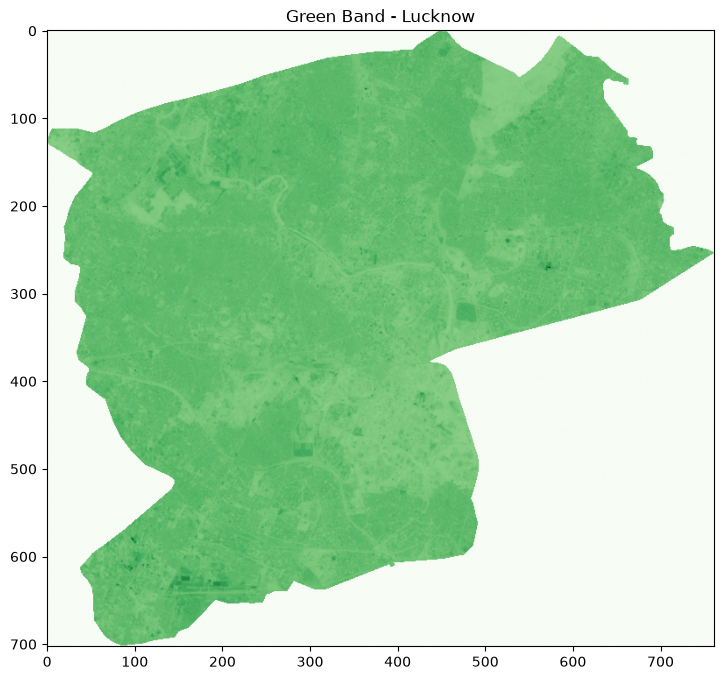

In [13]:
plt.figure(figsize=(10, 8))
plt.imshow(green_lucknow_reflectance, cmap="Greens")
plt.title("Green Band - Lucknow")
plt.show()

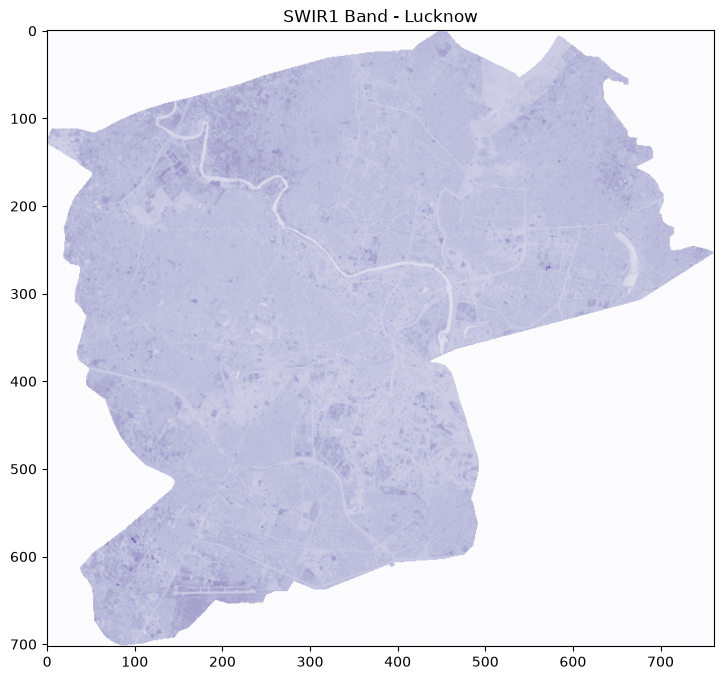

In [14]:
plt.figure(figsize=(10, 8))
plt.imshow(swir1_lucknow_reflectance, cmap="Purples")
plt.title("SWIR1 Band - Lucknow")
plt.show()

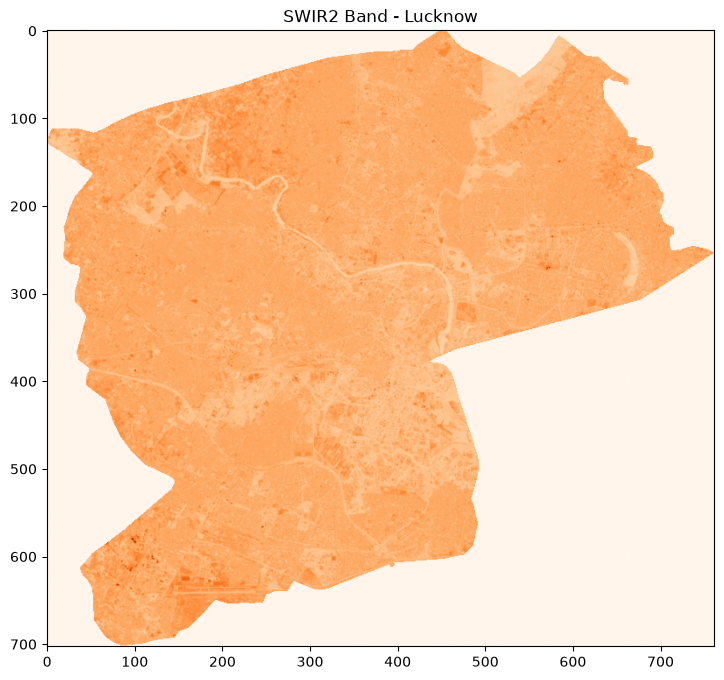

In [15]:
plt.figure(figsize=(10, 8))
plt.imshow(swir2_lucknow_reflectance, cmap="Oranges")
plt.title("SWIR2 Band - Lucknow")
plt.show()

### 7. Save clipped predictor bands

The Green, SWIR1 and SWIR2 bands have now been clipped to the Lucknow study area.

We save these clipped rasters as GeoTIFF so that the scientific raster data retain their spatial reference, transform and pixel structure.

In [16]:
from pathlib import Path
import rasterio

output_dir = Path("../data/processed/lucknow/fine/predictors")
output_dir.mkdir(parents=True, exist_ok=True)

def save_geotiff(array, profile, output_path):
    profile = profile.copy()
    profile.update({
        "driver": "GTiff",
        "count": 1,
        "dtype": array.dtype
    })

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(array, 1)

    print(f"Saved: {output_path}")

# Define output paths
green_out = output_dir / "green_lucknow_reflectance.tif"
swir1_out = output_dir / "swir1_lucknow_reflectance.tif"
swir2_out = output_dir / "swir2_lucknow_reflectance.tif"

# Save the clipped bands as GeoTIFF
save_geotiff(green_lucknow_reflectance, green_profile, green_out)
save_geotiff(swir1_lucknow_reflectance, swir1_profile, swir1_out)
save_geotiff(swir2_lucknow_reflectance, swir2_profile, swir2_out)

Saved: ..\data\processed\lucknow\fine\predictors\green_lucknow_reflectance.tif
Saved: ..\data\processed\lucknow\fine\predictors\swir1_lucknow_reflectance.tif
Saved: ..\data\processed\lucknow\fine\predictors\swir2_lucknow_reflectance.tif


In [17]:
from pathlib import Path

figure_dir = Path("../figures/lucknow/notebook_2")
figure_dir.mkdir(parents=True, exist_ok=True)

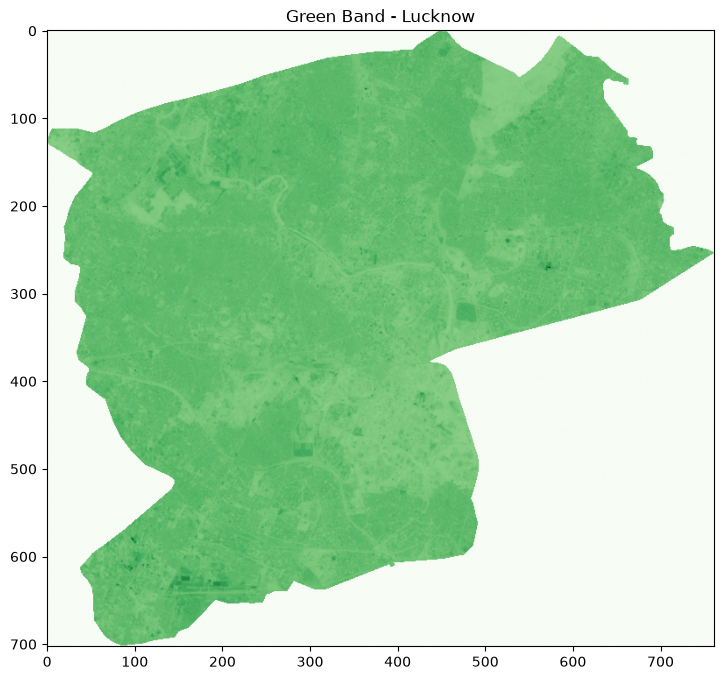

In [18]:
plt.figure(figsize=(10, 8))
plt.imshow(green_lucknow_reflectance, cmap="Greens")
plt.title("Green Band - Lucknow")
plt.savefig(figure_dir / "green_lucknow_reflectance.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

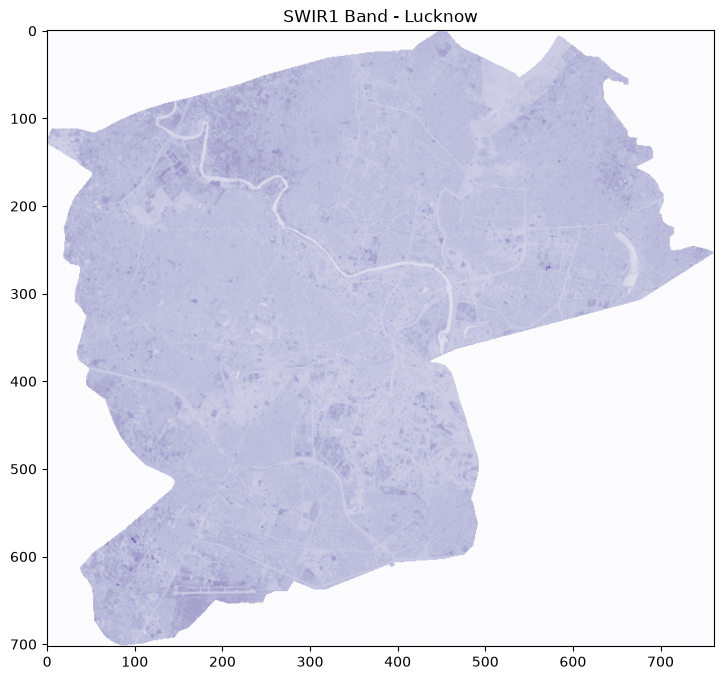

In [19]:
plt.figure(figsize=(10, 8))
plt.imshow(swir1_lucknow_reflectance, cmap="Purples")
plt.title("SWIR1 Band - Lucknow")
plt.savefig(figure_dir / "swir1_lucknow_reflectance.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

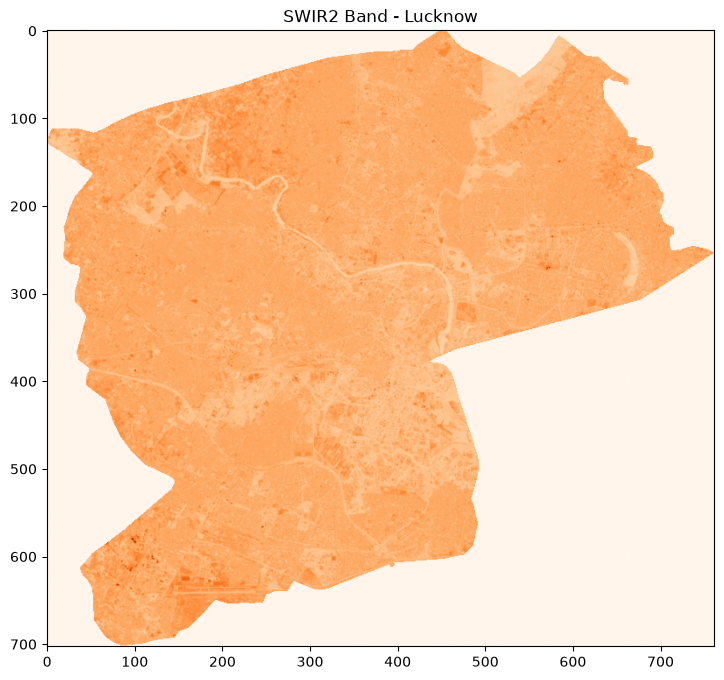

In [20]:
plt.figure(figsize=(10, 8))
plt.imshow(swir2_lucknow_reflectance, cmap="Oranges")
plt.title("SWIR2 Band - Lucknow")
plt.savefig(figure_dir / "swir2_lucknow_reflectance.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### 8. Calculating the Normalized Difference Buit-up Index

NDBI = ( SWIR1 - NIR ) / ( SWIR1 + NIR )

NDBI = ( B6 - B5 ) / ( B6 + B5 )

In [21]:
from pathlib import Path
import rasterio

# Use the project root already defined earlier in the notebook
processed_dir = PROJECT_ROOT / "data" / "processed" / "lucknow"/ "fine"/ "predictors"
nir_path = processed_dir / "nir_lucknow_reflectance.tif"

print("Looking for NIR file at:", nir_path)

if not nir_path.exists():
    raise FileNotFoundError(f"File not found: {nir_path}")

with rasterio.open(nir_path) as src:
    nir = src.read(1)
    nir_profile = src.profile

print("NIR path:", nir_path)
print("NIR shape:", nir.shape)
print("NIR CRS:", nir_profile["crs"])

Looking for NIR file at: d:\Projects\GeoAI-LST-Downscaling\data\processed\lucknow\fine\predictors\nir_lucknow_reflectance.tif
NIR path: d:\Projects\GeoAI-LST-Downscaling\data\processed\lucknow\fine\predictors\nir_lucknow_reflectance.tif
NIR shape: (703, 762)
NIR CRS: EPSG:32644


In [22]:
print("SWIR1")
print("min:", np.nanmin(swir1_lucknow_reflectance))
print("max:", np.nanmax(swir1_lucknow_reflectance))
print("mean:", np.nanmean(swir1_lucknow_reflectance))

print("\nNIR")
print("min:", np.nanmin(nir))
print("max:", np.nanmax(nir))
print("mean:", np.nanmean(nir))

print("\nSWIR1 sample:")
print(swir1_lucknow_reflectance.flatten()[:10])

print("\nNIR sample:")
print(nir.flatten()[:10])

SWIR1
min: 0
max: 44110
mean: 9371.458791157507

NIR
min: 0.094854996
max: 0.6753525
mean: 0.25222194

SWIR1 sample:
[0 0 0 0 0 0 0 0 0 0]

NIR sample:
[nan nan nan nan nan nan nan nan nan nan]


In [23]:
# Check valid SWIR1 and NIR values side by side

swir1_valid = swir1_lucknow_reflectance[
    (swir1_lucknow_reflectance > 0) & np.isfinite(swir1_lucknow_reflectance)
]

nir_valid = nir[np.isfinite(nir)]

print("SWIR1 valid:")
print("min:", swir1_valid.min())
print("max:", swir1_valid.max())
print("mean:", swir1_valid.mean())
print("samples:", swir1_valid[:10])

print("\nNIR valid:")
print("min:", nir_valid.min())
print("max:", nir_valid.max())
print("mean:", nir_valid.mean())
print("samples:", nir_valid[:10])

SWIR1 valid:
min: 9585
max: 44110
mean: 15944.454313600316
samples: [15714 15794 14974 16602 16177 16975 16151 16359 16267 17382]

NIR valid:
min: 0.094854996
max: 0.6753525
mean: 0.2522219
samples: [0.26205498 0.25782    0.25564748 0.26884753 0.25361252 0.2719825
 0.2576     0.27236748 0.2641725  0.2752    ]


In [24]:
swir1_test = swir1_lucknow_reflectance.astype(np.float32) / 100000.0

denominator = swir1_test + nir.astype(np.float32)

ndbi_test = np.divide(
    swir1_test - nir.astype(np.float32),
    denominator,
    out=np.full(denominator.shape, np.nan, dtype=np.float32),
    where=(denominator != 0) & np.isfinite(denominator)
)

print("Test NDBI:")
print("min:", np.nanmin(ndbi_test))
print("max:", np.nanmax(ndbi_test))
print("mean:", np.nanmean(ndbi_test))

Test NDBI:
min: -0.52347004
max: 0.013186339
mean: -0.2225873


In [25]:
swir1_test = swir1_lucknow_reflectance.astype(np.float32) / 100000.0

nir_float = nir.astype(np.float32)

denominator = swir1_test + nir_float

ndbi_test = np.divide(
    swir1_test - nir_float,
    denominator,
    out=np.full(denominator.shape, np.nan, dtype=np.float32),
    where=(denominator != 0) & np.isfinite(denominator)
)

print("Test NDBI min:", np.nanmin(ndbi_test))
print("Test NDBI max:", np.nanmax(ndbi_test))
print("Test NDBI mean:", np.nanmean(ndbi_test))

Test NDBI min: -0.52347004
Test NDBI max: 0.013186339
Test NDBI mean: -0.2225873


In [26]:
# Convert SWIR1 from scaled integer reflectance
# to the same 0–1 reflectance scale used by NIR.
swir1_float = (
    swir1_lucknow_reflectance.astype(np.float32) / 100000.0
)

nir_float = nir.astype(np.float32)

# Valid pixels require finite values in both inputs.
valid = (
    np.isfinite(swir1_float)
    & np.isfinite(nir_float)
    & (swir1_float > 0)
    & (nir_float > 0)
)

denominator = swir1_float + nir_float

ndbi = np.full(
    denominator.shape,
    np.nan,
    dtype=np.float32
)

ndbi[valid] = (
    (swir1_float[valid] - nir_float[valid])
    / denominator[valid]
)

print("NDBI min:", np.nanmin(ndbi))
print("NDBI max:", np.nanmax(ndbi))
print("NDBI mean:", np.nanmean(ndbi))

NDBI min: -0.52347004
NDBI max: 0.013186339
NDBI mean: -0.2225873


### 9. Saving the NDBI values

In [27]:
# Save NDBI as GeoTIFF

ndbi_out = output_dir / "ndbi_lucknow.tif"

save_geotiff(
    ndbi.astype("float32"),
    swir1_profile,
    ndbi_out
)

print(f"Saved NDBI to: {ndbi_out}")

Saved: ..\data\processed\lucknow\fine\predictors\ndbi_lucknow.tif
Saved NDBI to: ..\data\processed\lucknow\fine\predictors\ndbi_lucknow.tif


In [28]:
with rasterio.open(ndbi_out) as src:
    saved_ndbi = src.read(1)

    valid = saved_ndbi[np.isfinite(saved_ndbi)]

    print("Saved NDBI")
    print("Shape:", saved_ndbi.shape)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Dtype:", src.dtypes[0])
    print("NoData:", src.nodata)
    print("Min:", valid.min())
    print("Max:", valid.max())
    print("Mean:", valid.mean())

Saved NDBI
Shape: (703, 762)
CRS: EPSG:32644
Resolution: (30.0, 30.0)
Dtype: float32
NoData: 0.0
Min: -0.52347004
Max: 0.013186339
Mean: -0.2225873


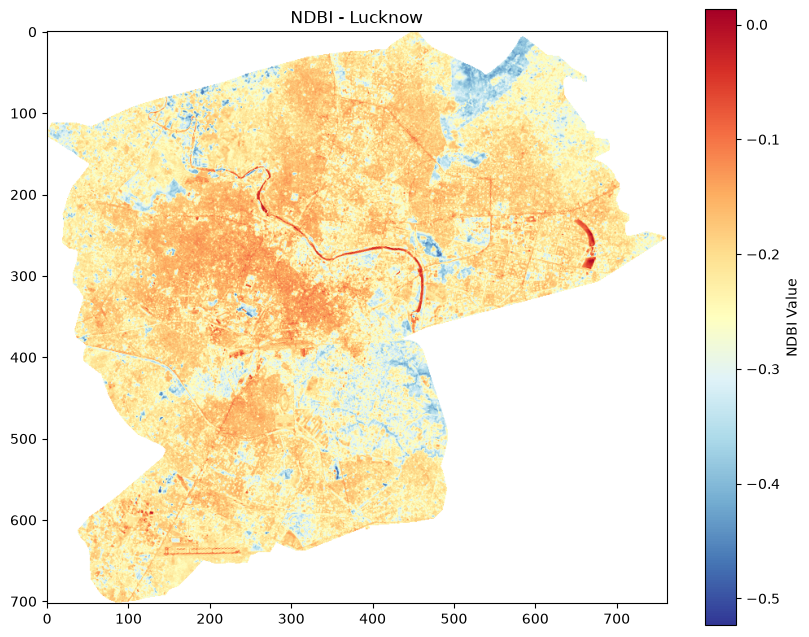

In [29]:
plt.figure(figsize=(10, 8))
plt.imshow(ndbi, cmap="RdYlBu_r")
plt.title("NDBI - Lucknow")
plt.colorbar(label="NDBI Value")
plt.savefig(figure_dir / "ndbi_lucknow.png", dpi=300, bbox_inches="tight")
plt.show()

### 10. Calculating Modified Normalized Difference Water Index

MNDWI = ( Green - SWIR1 ) / (Green + SWIR1)

MNDWI = ( B3 - B6 ) / ( B3 + B6 )

In [30]:

swir1_float = swir1_lucknow_reflectance.astype(np.float32)
green_float = green_lucknow_reflectance.astype(np.float32)

denominator = green_float + swir1_float 

mndwi = np.divide(
    green_float - swir1_float,
    denominator,
    out=np.full(denominator.shape, np.nan, dtype=np.float32),
    where=denominator != 0
)

print("MNDWI min:", np.nanmin(mndwi))
print("MNDWI max:", np.nanmax(mndwi))
print("MNDWI mean:", np.nanmean(mndwi))

MNDWI min: -0.3281944
MNDWI max: 0.06609564
MNDWI mean: -0.14413378


### 11. Saving the value of MNDWI

In [31]:
# Save MNDWI as GeoTIFF

mndwi_out = output_dir / "mndwi_lucknow.tif"

save_geotiff(
    mndwi.astype("float32"),
    swir1_profile,
    mndwi_out
)

print(f"Saved MNDWI to: {mndwi_out}")

Saved: ..\data\processed\lucknow\fine\predictors\mndwi_lucknow.tif
Saved MNDWI to: ..\data\processed\lucknow\fine\predictors\mndwi_lucknow.tif


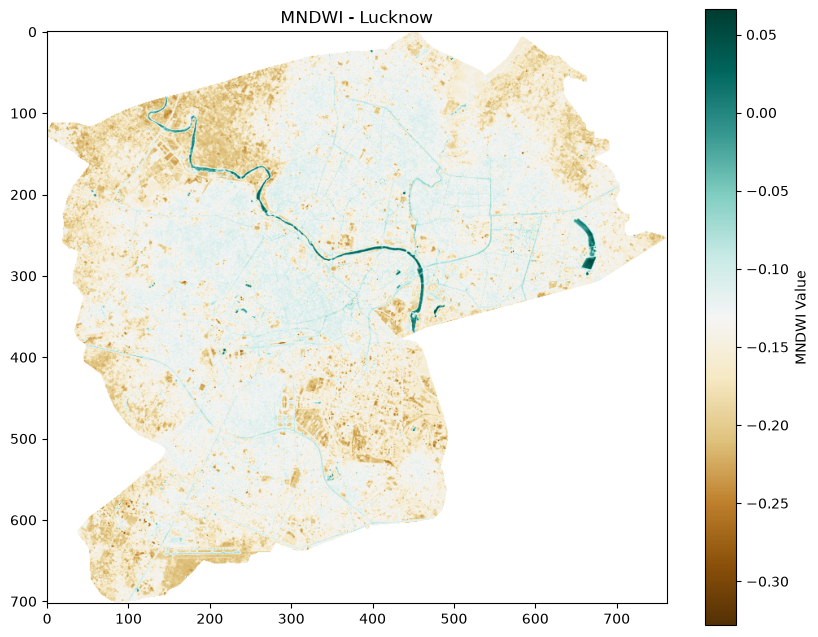

In [32]:
plt.figure(figsize=(10, 8))
plt.imshow(mndwi, cmap="BrBG")
plt.title("MNDWI - Lucknow")
plt.colorbar(label="MNDWI Value")
plt.savefig(figure_dir / "mndwi_lucknow.png", dpi=300, bbox_inches="tight")
plt.show()

## Notebook Summary

In this notebook, the additional spectral predictors required for LST downscaling were prepared for the Lucknow study area.

Completed:

- Green (B3)
- SWIR1 (B6)
- SWIR2 (B7)
- NDBI
- MNDWI

The predictor rasters were clipped to the Lucknow study area and saved as GeoTIFF files, with corresponding visualizations saved as PNG files.

DEM was considered as a potential predictor but is deferred from the current experimental setup.

### Next Step

The next notebook will focus on spatial preparation and alignment of the predictor variables before implementing the LST downscaling methods.